# MSE802 Assessment 2 — Task 3: Investigating a Quantum Code (Quantum Tic-Tac-Toe)

| Item | Detail |
|---|---|
| Original file | `Quantum_Tic_Tac_Toe__AS2.ipynb` (Lab 5, supplied by the lecturer; called *tic_tac_toe_quantum.ipynb* in the brief) |
| Learning outcomes | LO1, LO2, LO4 |

**Task question:** *Complete the provided code by filling in any missing instructions or comments, play multiple games, analyse the generated circuits, explain purpose, functionality, gameplay and circuit generation, and describe each gate used.*

### How to read this notebook
* Lines marked **`# [ADDED]`** were missing in the supplied code and were written by us.
* Lines marked **`# [FIXED]`** were in the supplied code but contained a bug.
* Lines marked **`# [CHANGED]`** were changed so the game also runs in VS Code / Jupyter (the original only worked in Google Colab).
* Every other line is original, with a comment added to explain it.

### Running in Google Colab?
Run the next cell first. In Colab it downloads the project from GitHub, installs the packages and moves into this task's folder. In VS Code / Jupyter it does nothing.

In [1]:
# ---------- Google Colab bootstrap (skipped automatically on your own PC) ----------
import os, sys, subprocess
from pathlib import Path
REPO_URL = "https://github.com/anishnz/quantumcomputing_YB_Anish.git"
REPO_DIR = Path("/content/quantumcomputing_YB_Anish")
TASK_DIR = "Task_3_Quantum_TicTacToe"
if "google.colab" in sys.modules and not (Path.cwd().parent / "common").exists():
    if not REPO_DIR.exists():                         # 1. download the project from GitHub
        subprocess.run(["git", "clone", "-q", REPO_URL, str(REPO_DIR)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",   # 2. install quantum packages
                    "cirq-core", "qiskit", "qiskit-aer", "pylatexenc"], check=True)
    os.chdir(REPO_DIR / "Assignment_2_Quantum" / TASK_DIR)     # 3. work inside this task's folder
    from google.colab import output                  # Task 3 buttons need Colab's widget manager
    output.enable_custom_widget_manager()
print("Working folder:", Path.cwd())

Working folder: /home/claude/Assignment_2_Quantum/Task_3_Quantum_TicTacToe


## 1. What was missing or wrong in the supplied code?

| # | Place | Problem in the supplied code | What we did |
|---|---|---|---|
| 1 | `make_move` – **Not** | comment "add an x gate" but no gate | `self.qc.x(cell)` |
| 2 | `make_move` – **O** | comment "rotation toward \|0⟩" but no gate | `self.qc.ry(+π/4, cell)` toward **\|1⟩** (see note) |
| 3 | `make_move` – **X** | comment "rotation toward \|1⟩" but no gate | `self.qc.ry(−π/4, cell)` toward **\|0⟩** (see note) |
| 4 | `make_move` – **SWAP** | comment "add a swap gate" but no gate | `self.qc.swap(cell, self.target)` |
| 5 | `countWinners` | `winners = ()` — empty, so nobody could ever win | the 8 winning lines (3 rows, 3 columns, 2 diagonals) |
| 6 | `make_move` – SWAP | inner `if self.target == cell` can never be true (dead code); SWAP with no target crashed | guard `self.target >= 0`, reset target after the swap |
| 7 | `new()` | empty tiles set to `''` but `__init__` uses `' '` | made consistent |
| 8 | imports / grid | `from google.colab import widgets` fails outside Colab | ipywidgets `GridBox` / `HBox` |

**Note on rotation direction (an important finding).** `measure()` maps bit **0 → 'X'** and bit **1 → 'O'**. The supplied comments said "O = rotation toward |0⟩" and "X = rotation toward |1⟩", which would make the **O** button help player **X**. That contradicts the game rules ("**O** turns the tile toward a tile owned by O"). We followed the rules: **O rotates toward |1⟩ (owned by O)** and **X rotates toward |0⟩ (owned by X)**, and we corrected the comments.

## 2. Imports

In [2]:
from __future__ import print_function        # kept from the original (harmless in Python 3)
import sys, math, random                     # small utilities
from pathlib import Path                     # file paths for saved evidence
import numpy as np                           # sqrt of board size, arrays
import pandas as pd                          # tables for the analysis
import matplotlib.pyplot as plt              # charts and circuit drawings
from IPython.display import display, clear_output   # redraw the board after each click
from ipywidgets import Button, Layout, GridBox, HBox, VBox, Output   # [CHANGED] replaces google.colab.widgets
from qiskit import QuantumCircuit, transpile # the game circuit and gate translation
import qiskit.qasm2                          # export the game circuit as QASM (for Quokka)
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator          # local simulator used by the game's Measure button

sys.path.insert(0, str(Path.cwd().parent / "common"))
import quokka_helper as qh                   # team helper (Quokka + fallback)

RESULTS = Path("results"); RESULTS.mkdir(exist_ok=True)
ROTATION = math.pi / 4                       # [ADDED] size of one X/O move: a quarter of the way to |0> or |1>

## 3. The `Board` class — the quantum part of the game

Each of the 9 tiles is **one qubit**. A tile's final owner is decided by measuring its qubit: **0 → X**, **1 → O**.

In [3]:
class Board:
    def __init__(self):
        self.qc = QuantumCircuit(9, 9)        # 9 qubits (one per tile) and 9 classical bits
        self.function = ''                    # which move button was pressed last ('Not','O','X','SWAP')
        self.target = -1                      # first tile chosen for a SWAP (-1 = none yet)
        self.tab = []                         # what the text board shows on each tile
        self.winsX = 0                        # number of winning lines for X after measuring
        self.winsO = 0                        # number of winning lines for O after measuring
        self.history = []                     # [ADDED] list of (move, tile) for the analysis section

        for idx in range(0, 9):
            self.tab.append({'default': str(idx), 'player': ' '})
            self.qc.reset(idx)                # make sure every qubit starts in |0>
            self.qc.h(idx)                    # Hadamard -> every tile starts 50 % X / 50 % O (undecided)
        self.qc.barrier()                     # visual line between "start" and "moves"

    def make_move(self, cell):
        cell = int(cell)
        if self.function == 'Not':
            self.qc.x(cell)                                   # [ADDED] X (NOT) gate: |0> <-> |1>, swaps X/O ownership
            self.tab[cell]['player'] += 'N - '
            self.history.append(('Not', cell))
        elif self.function == 'O':
            self.qc.ry(ROTATION, cell)                        # [ADDED] rotate a quarter turn toward |1> (owned by O)
            self.tab[cell]['player'] += "O - "
            self.history.append(('O', cell))
        elif self.function == 'X':
            self.qc.ry(-ROTATION, cell)                       # [ADDED] rotate a quarter turn toward |0> (owned by X)
            self.tab[cell]['player'] += "X - "
            self.history.append(('X', cell))
        elif self.function == 'SWAP' and self.target >= 0 and self.target != cell:   # [FIXED] needs a first tile
            self.qc.swap(cell, self.target)                   # [ADDED] SWAP gate: exchanges the two tiles' quantum states
            self.tab[cell]['player'] += "S - "
            self.tab[int(self.target)]['player'] += "S - "
            self.history.append(('SWAP', (self.target, cell)))
            self.target = -1                                  # [FIXED] clear the first tile after swapping

    def results(self):
        display(self.qc.draw('mpl'))           # show the final circuit that decided the game
        self.qc = QuantumCircuit(9, 9)         # empty circuit, ready for a new round (new() adds H again)

    def display(self):
        display(self.qc.draw('mpl'))           # show the circuit built so far

    def measure(self, seed=None):
        self.qc.barrier()
        for i in range(0, 9):
            self.qc.measure(i, i)              # qubit i -> classical bit i

        simulator = AerSimulator(seed_simulator=seed)   # [CHANGED] optional seed so recorded games can be repeated
        job = simulator.run(self.qc, shots=1)  # ONE shot = one real game result
        counts = job.result().get_counts()
        output = list(counts.keys())[0]        # e.g. '010011001'; Qiskit puts bit 8 on the LEFT

        for i in range(0, 9):
            if output[9 - 1 - i] == '0':       # read bit i from the right-hand end of the string
                self.tab[i]['player'] = 'X'    # 0 -> tile owned by X
            else:
                self.tab[i]['player'] = 'O'    # 1 -> tile owned by O
        self.winsX = self.countWinners('X')
        self.winsO = self.countWinners('O')
        return output

    def countWinners(self, player):
        # [ADDED] the 8 winning lines on a 3x3 board (tile numbers 0-8, row by row)
        winners = ((0, 1, 2), (3, 4, 5), (6, 7, 8),    # rows
                   (0, 3, 6), (1, 4, 7), (2, 5, 8),    # columns
                   (0, 4, 8), (2, 4, 6))               # diagonals
        wins = 0
        for i in range(len(winners)):
            won = True
            for j in range(len(winners[0])):
                if not self.tab[winners[i][j]]['player'] == player:
                    won = False                # one tile in the line belongs to someone else
            if won:
                wins = wins + 1                # a full line of the same player
        return wins

    def new(self):
        self.tab.clear()
        self.history = []                      # [ADDED] forget the old moves
        self.target = -1                       # [ADDED] no SWAP in progress
        for idx in range(0, 9):
            self.tab.append({'default': str(idx), 'player': ' '})   # [FIXED] ' ' to match __init__
            self.qc.reset(idx)
            self.qc.h(idx)
        self.qc.barrier()

## 4. The `Game` class — buttons and screen (classical part)

The game logic is unchanged. Only the layout was moved from `google.colab.widgets.Grid` to standard `ipywidgets` so it works in VS Code, JupyterLab and Colab.

In [4]:
class Game:
    def __init__(self):
        self.selecting = False                # True while waiting for the first tile of a SWAP
        self.board = Board()
        self.boardbutton_list = []
        for i in range(0, 9):                 # one button per tile, labelled 0..8
            button = Button(description=str(i), layout=Layout(width='86px', height='60px'))
            button.on_click(self.handle_game)
            self.boardbutton_list.append(button)

        self.funcbutton_list = []
        self.newButton('Measure')             # ends the round
        self.newButton('Not')
        self.newButton('O')
        self.newButton('X')
        self.newButton('SWAP')
        self.printmenu()
        self.printBoard()

    def newButton(self, name):
        function = Button(description=name, layout=Layout(width='86px', height='30px'))
        function.on_click(self.handle_game)
        self.funcbutton_list.append(function)

    def handle_game(self, b):
        try:
            if b.description == 'Measure':
                clear_output()
                self.replay()
                self.board.measure()
                self.scoreboard()
                self.printBoard()
                self.board.results()

            if b.description == 'Replay':
                clear_output()
                self.board.new()
                self.printmenu()
                self.printBoard()

            if int(b.description) >= 0:       # a tile button (raises ValueError for text buttons)
                if self.selecting:
                    self.board.target = int(b.description)     # first tile of a SWAP
                else:
                    clear_output()
                    self.printmenu()
                    self.board.make_move(int(b.description))  # add the gate for the chosen move
                    self.printBoard()
                    self.board.display()
            self.selecting = False
        except ValueError:                    # a move button was pressed (Not, O, X, SWAP)
            self.board.function = b.description
            self.selecting = False
            if self.board.function == 'SWAP':
                self.selecting = True         # next tile click = first tile of the swap

    def printmenu(self):
        display(HBox(self.funcbutton_list))   # [CHANGED] one row of 5 move buttons

    def scoreboard(self):
        print("X wins: " + str(self.board.winsX) + "    O wins: " + str(self.board.winsO))

    def replay(self):
        rep = Button(description="Replay")
        rep.on_click(self.handle_game)
        display(rep)

    def printBoard(self):
        size = int(np.sqrt(9))                # 3x3 board
        cells = []
        for idx in range(9):                  # [CHANGED] each tile = its move history + its button
            label = Output()
            with label:
                print(self.board.tab[idx]['player'] or ' ')
            cells.append(VBox([label, self.boardbutton_list[idx]]))
        display(GridBox(cells, layout=Layout(grid_template_columns=f"repeat({size}, 100px)")))

## 5. Play the game (interactive)

Click a move (**Not**, **O**, **X**, **SWAP**), then a tile. For SWAP click two tiles. Press **Measure** to collapse the board and count winning lines.

* **Measure** – runs the circuit once and reads every tile.
* **Not** – flips a tile's ownership (does nothing to an undecided 50/50 tile).
* **O / X** – nudges a tile a quarter turn toward O / X.
* **SWAP** – exchanges two tiles.

In [5]:
game = Game()        # buttons appear below when the notebook is run in Jupyter / VS Code

GridBox(children=(VBox(children=(Output(), Button(description='0', layout=Layout(height='60px', width='86px'),…

## 6. Recorded games for the analysis

Button clicks cannot be saved in a notebook, so we replay four games as **scripts** that call exactly the same `Board.make_move` and `Board.measure` code. For each game we save:

1. the generated circuit (picture + QASM),
2. the one-shot game result and the number of X and O lines,
3. a **1000-shot** run of the same circuit, which estimates each tile's chance of becoming X and each player's chance of winning.

In [6]:
WIN_LINES = ((0,1,2),(3,4,5),(6,7,8),(0,3,6),(1,4,7),(2,5,8),(0,4,8),(2,4,6))

def lines_won(bitstring, player_bit):
    """Number of winning lines for one player in one 9-bit result (Qiskit order)."""
    owner = [bitstring[8 - i] for i in range(9)]               # owner[i] = bit of tile i
    return sum(all(owner[t] == player_bit for t in line) for line in WIN_LINES)

def play_scripted(name, moves, seed):
    """Replay a list of (move, tile) or ('SWAP', (a, b)) using the real Board code."""
    board = Board()
    for move, tile in moves:
        board.function = move
        if move == 'SWAP':
            board.target = tile[0]                               # first click
            board.make_move(tile[1])                             # second click
        else:
            board.make_move(tile)
    game_circuit = board.qc.copy()                               # circuit before measurement
    one_shot = board.measure(seed=seed)                          # the actual game result

    # ---- 1000-shot study of the same circuit (local simulator, same as the game) ----
    study = game_circuit.copy()
    study.barrier(); study.measure(range(9), range(9))
    counts = AerSimulator(seed_simulator=seed).run(study, shots=1000).result().get_counts()
    p_x = [sum(c for b, c in counts.items() if b[8 - i] == '0') / 1000 for i in range(9)]
    x_wins = sum(c for b, c in counts.items() if lines_won(b, '0') > lines_won(b, '1'))
    o_wins = sum(c for b, c in counts.items() if lines_won(b, '1') > lines_won(b, '0'))
    draws = 1000 - x_wins - o_wins

    # ---- evidence files ----
    fig = game_circuit.draw('mpl', fold=-1)
    fig.savefig(RESULTS / f"{name}_circuit.png", dpi=170, bbox_inches="tight"); plt.close(fig)
    board_text = "\n".join(" ".join(board.tab[r*3 + c]['player'] for c in range(3)) for r in range(3))
    return {"name": name, "moves": moves, "gates": dict(game_circuit.count_ops()),
            "depth": game_circuit.depth(), "one_shot": one_shot, "board": board_text,
            "X lines": board.winsX, "O lines": board.winsO, "P(X) per tile": p_x,
            "X wins /1000": x_wins, "O wins /1000": o_wins, "draws /1000": draws,
            "circuit": game_circuit}

In [7]:
games = [
    ("game1_no_moves",  [], 11),                                            # baseline: pure superposition
    ("game2_diagonals", [('X', 0), ('X', 4), ('X', 8), ('O', 2), ('O', 6)], 22),
    ("game3_not_gate",  [('X', 4), ('X', 4), ('Not', 4), ('O', 0), ('Not', 1)], 33),
    ("game4_swap",      [('X', 0), ('X', 0), ('O', 4), ('O', 4), ('SWAP', (0, 8)), ('X', 2), ('X', 2), ('X', 2)], 44),
]
records = [play_scripted(n, m, s) for n, m, s in games]

summary = pd.DataFrame([{k: r[k] for k in ["name", "gates", "depth", "X lines", "O lines",
                                           "X wins /1000", "O wins /1000", "draws /1000"]} for r in records])
display(summary)
summary.to_csv(RESULTS / "task3_games_summary.csv", index=False)

for r in records:
    print(f"\n=== {r['name']} | moves: {r['moves']}")
    print("one-shot result (bit 8 ... bit 0):", r["one_shot"])
    print(r["board"])
    print("P(tile becomes X):", [round(p, 2) for p in r["P(X) per tile"]])

,name,gates,depth,X lines,O lines,X wins /1000,O wins /1000,draws /1000
0,game1_no_moves,"{'reset': 9, 'h': 9, 'barrier': 1}",2,4,0,392,405,203
1,game2_diagonals,"{'reset': 9, 'h': 9, 'ry': 5, 'barrier': 1}",3,4,0,705,210,85
2,game3_not_gate,"{'reset': 9, 'h': 9, 'ry': 3, 'x': 2, 'barrier...",5,0,2,135,694,171
3,game4_swap,"{'reset': 9, 'h': 9, 'ry': 7, 'barrier': 1, 's...",5,0,2,404,289,307



=== game1_no_moves | moves: []
one-shot result (bit 8 ... bit 0): 000001001
O X X
O X X
X X X
P(tile becomes X): [0.51, 0.48, 0.5, 0.47, 0.51, 0.49, 0.51, 0.49, 0.5]

=== game2_diagonals | moves: [('X', 0), ('X', 4), ('X', 8), ('O', 2), ('O', 6)]
one-shot result (bit 8 ... bit 0): 001001000
X X X
O X X
O X X
P(tile becomes X): [0.86, 0.49, 0.15, 0.47, 0.87, 0.49, 0.16, 0.49, 0.87]

=== game3_not_gate | moves: [('X', 4), ('X', 4), ('Not', 4), ('O', 0), ('Not', 1)]
one-shot result (bit 8 ... bit 0): 111011100
X X O
O O X
O O O
P(tile becomes X): [0.17, 0.49, 0.5, 0.47, 0.0, 0.48, 0.51, 0.48, 0.5]

=== game4_swap | moves: [('X', 0), ('X', 0), ('O', 4), ('O', 4), ('SWAP', (0, 8)), ('X', 2), ('X', 2), ('X', 2)]
one-shot result (bit 8 ... bit 0): 001111001
O X X
O O O
O X X
P(tile becomes X): [0.52, 0.48, 0.85, 0.47, 0.0, 0.48, 0.52, 0.48, 1.0]


### Circuit generated by Game 4 (rotations, SWAP and over-rotation)

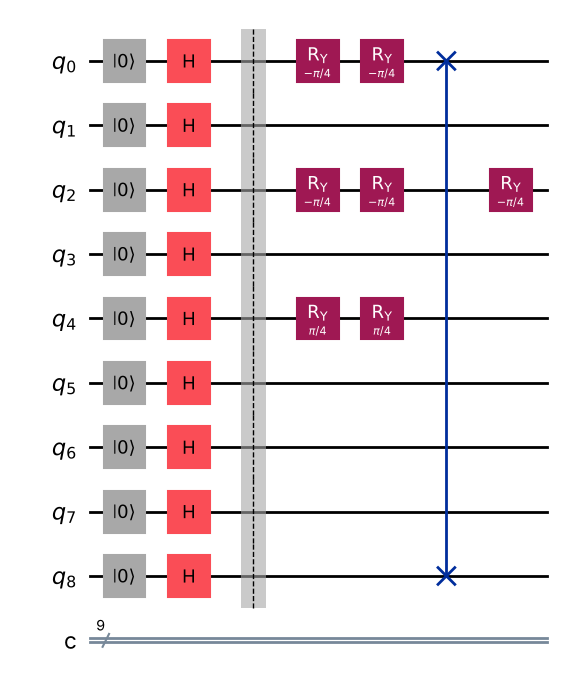

In [8]:
display(records[3]["circuit"].draw('mpl', fold=-1))

### Chance that each tile becomes X (1000 shots per game)

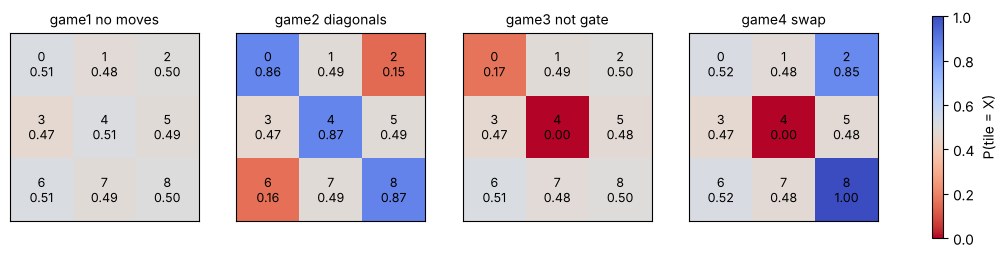

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, r in zip(axes, records):
    grid = np.array(r["P(X) per tile"]).reshape(3, 3)       # tile 0 top-left ... tile 8 bottom-right
    im = ax.imshow(grid, cmap="coolwarm_r", vmin=0, vmax=1)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{3*i+j}\n{grid[i, j]:.2f}", ha="center", va="center", fontsize=9)
    ax.set_title(r["name"].replace("_", " "), fontsize=10); ax.set_xticks([]); ax.set_yticks([])
fig.colorbar(im, ax=axes, shrink=0.8, label="P(tile = X)")
fig.savefig(RESULTS / "task3_tile_probabilities.png", dpi=200, bbox_inches="tight")
plt.show()

## 7. Theory check: why a single X move gives about 85 % and three X moves go back to 85 %

A tile starts at $|+\rangle$, i.e. angle $\theta = \pi/2$ on the Bloch sphere ($P(0)=\cos^2(\theta/2)$). Each X move applies $R_y(-\pi/4)$, so $\theta$ drops by $\pi/4$:

| X moves on a tile | θ | $P(\text{X}) = \cos^2(\theta/2)$ |
|---|---|---|
| 0 | π/2 | 0.500 |
| 1 | π/4 | 0.854 |
| 2 | 0 | 1.000 |
| 3 | −π/4 | 0.854 (over-rotation) |

This is a real quantum effect: moves are **rotations**, not counters, so "too many" moves on one tile start to undo themselves.

In [10]:
for k in range(4):
    theta = math.pi / 2 - k * ROTATION
    print(f"{k} X-moves: P(X) theory = {math.cos(theta / 2) ** 2:.3f}")
print("Game 4, tile 2 had 3 X-moves -> measured P(X) =", round(records[3]["P(X) per tile"][2], 3))

0 X-moves: P(X) theory = 0.500
1 X-moves: P(X) theory = 0.854
2 X-moves: P(X) theory = 1.000
3 X-moves: P(X) theory = 0.854
Game 4, tile 2 had 3 X-moves -> measured P(X) = 0.854


## 8. (Optional) Run a game circuit on Quokka

The game itself uses the local simulator (as in the original). To link Task 3 with the hardware, the Game 2 circuit is translated to basic gates (H, RY, X, CX), exported to QASM and sent to Quokka with 1000 shots. If Quokka is offline, the helper uses the local simulator and labels it.

In [11]:
qc = records[1]["circuit"].copy()
qc.data = [ins for ins in qc.data if ins.operation.name != "reset"]   # qubits already start in |0>
qc.measure_all(add_bits=False)                                       # measure all 9 tiles
basic = transpile(qc, basis_gates=["h", "ry", "x", "cx"], optimization_level=0)
run = qh.run_qasm(qiskit.qasm2.dumps(basic), shots=1000, label="task3_game2_quokka", save_dir=RESULTS)
p_x_device = [sum(c for b, c in run["counts"].items() if b[8 - i] == '0') / 1000 for i in range(9)]
print("Source:", run["source"])
print("P(X) per tile:", [round(p, 2) for p in p_x_device])

Source: LOCAL SIMULATOR (Qiskit Aer) - Quokka was not reachable
P(X) per tile: [0.87, 0.5, 0.13, 0.51, 0.86, 0.5, 0.14, 0.53, 0.87]


## 9. Summary

* The game turns every move into a **gate on a qubit**: X/O = $R_y(\mp\pi/4)$, Not = $X$, SWAP = SWAP, start = $H$.
* The board shown on screen is only a history of moves; the **circuit is the true state**, and the winner is only known after measurement.
* The full analysis (purpose, gameplay dynamics, circuit generation, gate descriptions) is in the group report, Task 3 section.